# 04 · ข้อ 3 ผู้โดยสารระหว่างประเทศ ขาเข้า vs ขาออก
ผู้รับผิดชอบ: สมาชิก C · ต้องรัน `01_cleaning.ipynb` (หรือ `python src/run_all.py`) ก่อน

**คำถาม:** จำนวนผู้โดยสารระหว่างประเทศขาเข้าและขาออกมีความแตกต่างกันอย่างไร เมื่อจำแนกตามรูปแบบการเดินทาง เปรียบเทียบรายเดือน และวิเคราะห์ความผันผวนภายในปี

โค้ดทั้งหมดอยู่ใน `src/q3_intl.py` (ตรวจด้วย `pytest tests/test_q3_intl.py`) notebook นี้มีหน้าที่**เรียกฟังก์ชันและแสดงผล**พร้อมคำอธิบาย

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import prep
import features
import plots

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
_ = plots.setup_style()
import q3_intl

df = prep.load_clean()
print(df.shape)

(18705, 18)


## 1. Feature Selection

| Feature ต้นฉบับ | เหตุผล |
|---|---|
| `purpose` | เลือกเฉพาะ international |
| `mode` | จำแนกตามรูปแบบการเดินทาง (ถนน/น้ำ/ราง/อากาศ) |
| `port`, `direction` | จับคู่ขาเข้า–ขาออกของท่าเดียวกัน (7 คู่) |
| `date`, `value` | รวมเป็นรายเดือน |

## 2. Data Preparation

In [2]:
rows = q3_intl.select_rows(df)   # error ถ้ามีท่าที่ไม่มีครบทั้งขาเข้าและขาออก
display(rows.groupby(["mode", "port"])["direction"].unique())
print("เดือนที่ข้อมูลไม่ครบ (ใช้ avg_daily × จำนวนวัน แทนผลรวมดิบ):")
q3_intl.coverage_table(rows)

mode   port                      
air    ท่าอากาศยานดอนเมือง           [departure, arrival]
       ท่าอากาศยานภูมิภาค            [departure, arrival]
       ท่าอากาศยานสุวรรณภูมิ         [departure, arrival]
       ท่าอากาศยานอื่น ๆ ของ ทอท.    [departure, arrival]
rail   รถไฟ                          [departure, arrival]
road   รถ บขส.                       [departure, arrival]
water  ท่าเรือด่านชายแดน             [departure, arrival]
Name: direction, dtype: object

เดือนที่ข้อมูลไม่ครบ (ใช้ avg_daily × จำนวนวัน แทนผลรวมดิบ):


,year_be,mode,port,direction,year_month,days,valid_days,total,avg_daily,coverage
121,2568,road,รถ บขส.,arrival,2025-02,28,27,17089.0,632.925926,0.964286
122,2568,road,รถ บขส.,arrival,2025-03,31,30,16561.0,552.033333,0.967742
123,2568,road,รถ บขส.,arrival,2025-04,30,29,22787.0,785.758621,0.966667
129,2568,road,รถ บขส.,arrival,2025-10,31,30,14488.0,482.933333,0.967742
130,2568,road,รถ บขส.,arrival,2025-11,30,29,14891.0,513.482759,0.966667
131,2568,road,รถ บขส.,arrival,2025-12,31,30,16273.0,542.433333,0.967742
133,2568,road,รถ บขส.,departure,2025-02,28,27,41428.0,1534.370370,0.964286
134,2568,road,รถ บขส.,departure,2025-03,31,30,39035.0,1301.166667,0.967742
135,2568,road,รถ บขส.,departure,2025-04,30,29,47933.0,1652.862069,0.966667
137,2568,road,รถ บขส.,departure,2025-06,30,29,29704.0,1024.275862,0.966667


## 3. Feature Engineering

| Feature ใหม่ | สร้างจาก | สูตร / เงื่อนไข | ประโยชน์ |
|---|---|---|---|
| `arrival`, `departure` (รายเดือน) | `value`, `direction`, `date` | รวมรายเดือนต่อ mode; เดือนที่ขาดบางวันใช้ `avg_daily × days` | ระดับรายเดือนที่ไม่ต่ำเกินจริงเพราะวันว่าง |
| `net_flow` | `arrival`, `departure` | `arrival − departure` | ทิศทางสุทธิ |
| `arr_dep_ratio` | `arrival`, `departure` | `arrival / departure` | เทียบ mode ที่ขนาดต่างกันมากได้ |
| `mom_pct_arrival`, `mom_pct_departure` | รายเดือน | % เปลี่ยนจากเดือนก่อนภายใน mode | หาเดือนที่เปลี่ยนแปลงมาก |
| `mode_share` | `arrival + departure` | สัดส่วนของ mode ต่อยอดระหว่างประเทศของเดือน | mode ใดเป็นหลัก |
| `cv_within_year` | รายเดือน | `std / mean` ต่อ mode × direction | ความผันผวนภายในปีเป็นตัวเลขเดียว |

In [3]:
monthly = q3_intl.add_flow_features(q3_intl.monthly_flows(rows))
monthly.round(3).head(12)

,mode,year_month,month,arrival,departure,net_flow,arr_dep_ratio,mom_pct_arrival,mom_pct_departure,mode_share
0,air,2025-01,1,4026061.0,3551832.0,474229.0,1.134,NaN,NaN,0.968
1,air,2025-02,2,3348433.0,3307348.0,41085.0,1.012,-16.831,-6.883,0.968
2,air,2025-03,3,3213908.0,3195836.0,18072.0,1.006,-4.018,-3.372,0.967
3,air,2025-04,4,3171097.0,2900733.0,270364.0,1.093,-1.332,-9.234,0.963
4,air,2025-05,5,2695972.0,2540513.0,155459.0,1.061,-14.983,-12.418,0.968
5,air,2025-06,6,2658461.0,2278626.0,379835.0,1.167,-1.391,-10.308,0.964
6,air,2025-07,7,3031870.0,2515909.0,515961.0,1.205,14.046,10.413,0.965
7,air,2025-08,8,2936113.0,2756506.0,179607.0,1.065,-3.158,9.563,0.967
8,air,2025-09,9,2634220.0,2288520.0,345700.0,1.151,-10.282,-16.978,0.962
9,air,2025-10,10,3259678.0,2769458.0,490220.0,1.177,23.744,21.015,0.966


In [4]:
# ยอดทั้งปี 2568 ต่อรูปแบบการเดินทาง
year = monthly.groupby("mode")[["arrival", "departure", "net_flow"]].sum()
year["arr_dep_ratio"] = year["arrival"] / year["departure"]
year["share"] = (year["arrival"] + year["departure"]) / (year["arrival"] + year["departure"]).sum()
year.round(3)

,arrival,departure,net_flow,arr_dep_ratio,share
mode,,,,,
air,3.854977e+07,3.456630e+07,3983477.000,1.115,0.967
rail,1.188250e+05,1.166040e+05,2221.000,1.019,0.003
road,2.057796e+05,4.627286e+05,-256949.004,0.445,0.009
water,8.122800e+05,7.864150e+05,25865.000,1.033,0.021


In [5]:
vol = q3_intl.volatility_table(monthly)
vol.round(3)

,mode,direction,mean_monthly,std_monthly,cv_within_year,peak_month,low_month
0,rail,departure,9717.000,2010.287,0.207,1,12
1,rail,arrival,9902.083,1893.375,0.191,1,12
2,road,arrival,17148.297,2874.977,0.168,4,9
3,road,departure,38560.714,6071.395,0.157,4,5
4,air,departure,2880524.750,431975.718,0.150,1,6
5,air,arrival,3212481.167,478528.109,0.149,12,9
6,water,departure,65534.583,7507.361,0.115,1,5
7,water,arrival,67690.000,6949.684,0.103,1,5


## 4. Visualization

### กราฟที่ 1: ขาเข้า vs ขาออก รายเดือน แยกตามรูปแบบ (small multiples)

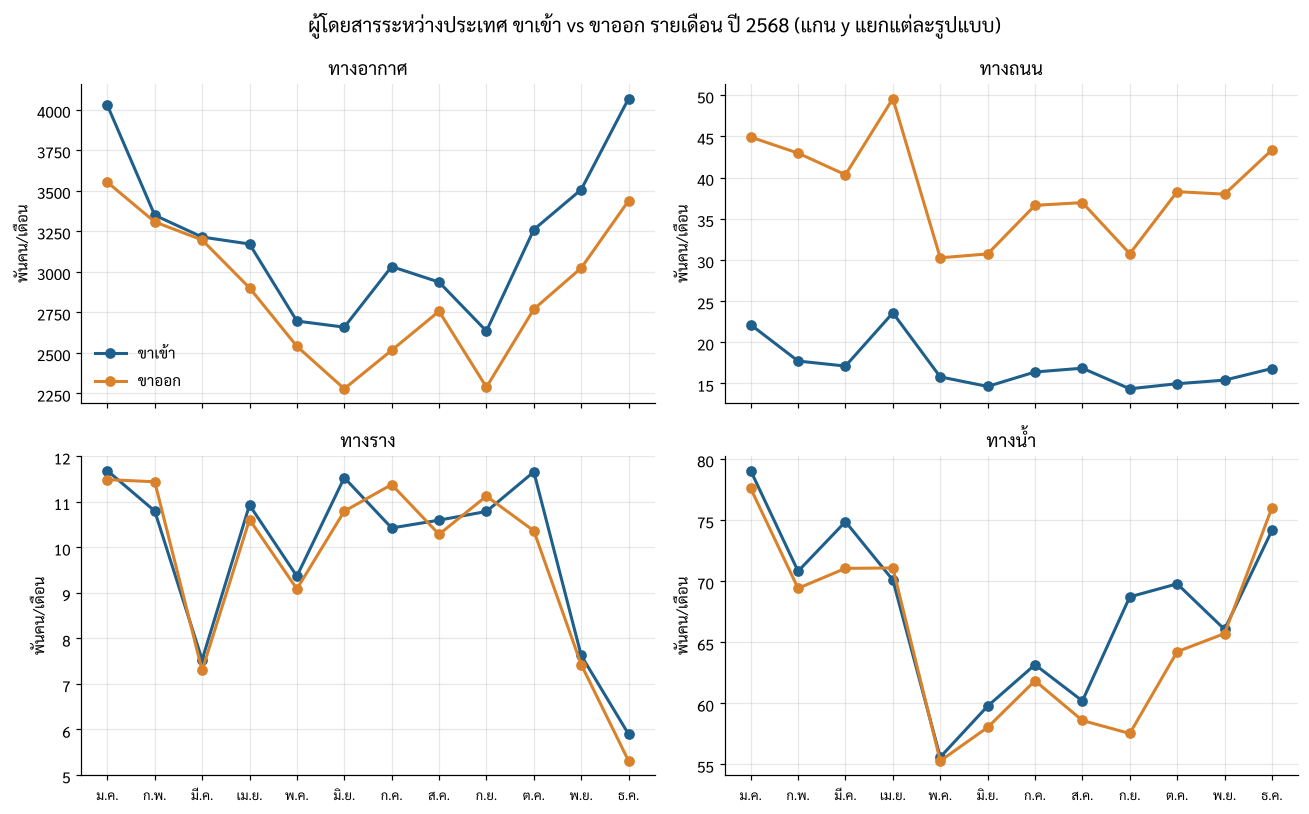

In [6]:
fig = q3_intl.plot_arrival_departure(monthly)
plots.save_fig(fig, "q3_arrival_departure"); plt.show()

> ✍️ **ร่างการตีความ** เขียนจากผลที่รันจริง ทีมต้องอ่านทวนและปรับให้เป็นคำของตัวเองก่อนใส่รายงาน

เลือก line chart แยก 4 panel แต่ละรูปมีแกน y ของตัวเอง เพราะทางอากาศใหญ่กว่า mode อื่นหลายสิบถึงหลายร้อยเท่า ถ้าใช้แกนเดียว ทางถนน/ราง/น้ำจะเป็นเส้นแบน
- **ทางอากาศ** ขาเข้ามากกว่าขาออกทุกเดือน สูงสุด ธ.ค.–ม.ค. (ฤดูท่องเที่ยว) ต่ำสุด มิ.ย. และ ก.ย.
- **ทางถนน** ขาออกมากกว่าขาเข้าประมาณ 2 เท่าทุกเดือน และมีจุดพีคใน เม.ย.
- **ทางรางและทางน้ำ** ขาเข้าและขาออกใกล้เคียงกัน ทางรางลดลงชัดใน มี.ค. และ ธ.ค.

### กราฟที่ 2: อัตราส่วนขาเข้าต่อขาออก

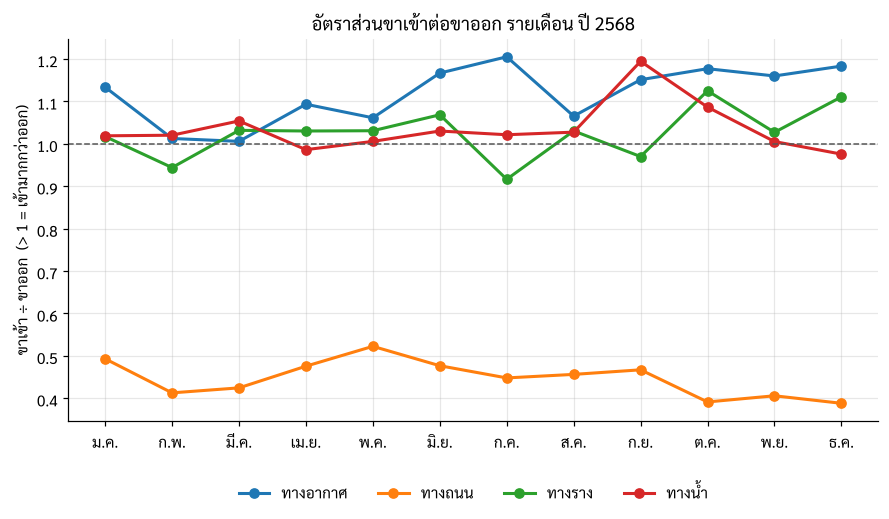

In [7]:
fig = q3_intl.plot_arr_dep_ratio(monthly)
plots.save_fig(fig, "q3_arr_dep_ratio"); plt.show()

> ✍️ **ร่างการตีความ** เขียนจากผลที่รันจริง ทีมต้องอ่านทวนและปรับให้เป็นคำของตัวเองก่อนใส่รายงาน

ใช้อัตราส่วนเพื่อให้ทุก mode อยู่บนสเกลเดียวกันได้ (เส้น 1.0 = สมดุล)
- ทางอากาศอยู่ระหว่าง 1.01–1.21 ตลอดปี (สมดุลที่สุดช่วง ก.พ.–มี.ค.)
- ทางถนนอยู่ระหว่าง 0.39–0.52 ตลอดปี ซึ่ง**คงที่ผิดปกติ** น่าจะมาจากวิธีนับหรือขอบเขตของข้อมูล (เช่น เส้นทางที่ บขส. รายงาน) มากกว่าพฤติกรรมการเดินทางจริง ควรระบุเป็นข้อจำกัด
- ทางรางและทางน้ำแกว่งรอบ 1.0 (ทางน้ำสูงสุด ก.ย. 1.19)

### กราฟที่ 3: ความผันผวนภายในปี (CV)

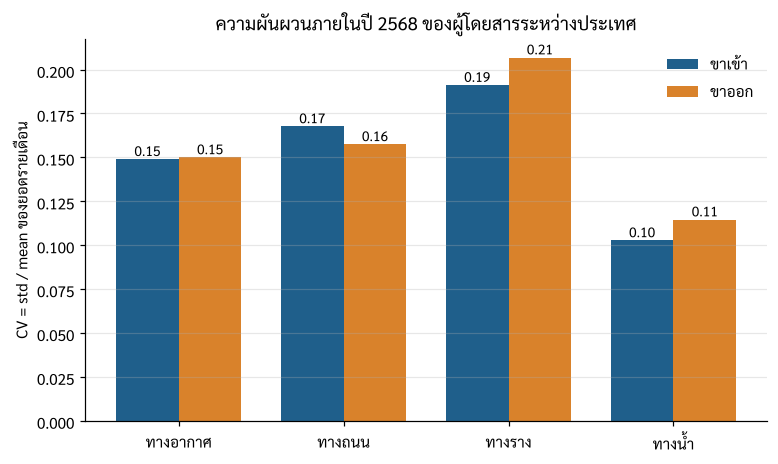

In [8]:
fig = q3_intl.plot_volatility(vol)
plots.save_fig(fig, "q3_volatility"); plt.show()

> ✍️ **ร่างการตีความ** เขียนจากผลที่รันจริง ทีมต้องอ่านทวนและปรับให้เป็นคำของตัวเองก่อนใส่รายงาน

ใช้ CV (std/mean) แทน std เพราะ std ของทางอากาศจะใหญ่ที่สุดเสมอเพียงเพราะมีขนาดใหญ่ CV ทำให้เทียบความผันผวนเชิงสัมพัทธ์ได้
- ทางรางผันผวนมากที่สุด (CV 0.19–0.21) ทางน้ำผันผวนน้อยที่สุด (0.10–0.11) ส่วนทางอากาศและทางถนนอยู่ระหว่างกลาง (0.15–0.17)
- ขาเข้าและขาออกของแต่ละ mode มี CV ใกล้กัน แปลว่าฤดูกาลส่งผลต่อทั้งสองทิศพร้อมกัน

## 5. Analysis & Findings
> ✍️ **ร่างการตีความ** เขียนจากผลที่รันจริง ทีมต้องอ่านทวนและปรับให้เป็นคำของตัวเองก่อนใส่รายงาน

**คำตอบ (ปี 2568)**
1. **ทางอากาศเป็นช่องทางหลัก** (ประมาณ 97% ของผู้โดยสารระหว่างประเทศทุกเดือน) ขาเข้า 38.55 ล้าน vs ขาออก 34.57 ล้าน (สุทธิ +3.98 ล้าน) ขาเข้ามากกว่าขาออกทุกเดือน
2. **ทางถนนกลับทิศ** ขาออก 462,729 vs ขาเข้า 205,780 (ขาออกมากกว่า 2.2 เท่า) และอัตราส่วนคงที่ทั้งปี
3. **ทางรางและทางน้ำใกล้สมดุล** (อัตราส่วนทั้งปี ≈ 1.02–1.03)
4. **ฤดูกาล:** ทางอากาศสูงช่วง ธ.ค.–ม.ค. และต่ำช่วง มิ.ย./ก.ย. ทางรางผันผวนมากที่สุด ส่วนทางน้ำคงที่ที่สุด

**ข้อจำกัด**
- ข้อมูลนับเป็น “เที่ยวผ่านด่าน” ไม่ใช่ “คน” คนเดียวที่เข้าและออกจึงถูกนับสองครั้ง และไม่มีข้อมูลสัญชาติ จึงแยกนักท่องเที่ยวต่างชาติกับคนไทยไม่ได้
- อัตราส่วนของทางถนนที่คงที่ผิดปกติอาจเป็นผลจากวิธีเก็บข้อมูล
- รถ บขส. มีวันว่างใน 6 เดือน จึงใช้ค่าประมาณ `avg_daily × จำนวนวัน`

## 6. บันทึก Prepared Dataset

In [9]:
monthly.to_csv(prep.PREPARED_DIR / q3_intl.OUTPUT_FILE, index=False, encoding="utf-8-sig")
print(q3_intl.OUTPUT_FILE, monthly.shape)

q3_international_monthly.csv (48, 10)
